# Session 05: Generated Text as Data

**Student implementer and maintainer:** YQ-HA. This notebook records code typed,
executed, and adapted while following the instructor during class, together with
the student's post-course completions and maintenance.

**Course:** Tyler Shoemaker, [Introduction to Interpretability for Language Models](https://digitaltheorylab.github.io/2026_interpretability-reader/).
Reference implementation: [05_text.md](https://github.com/digitaltheorylab/2026_interpretability-reader/blob/main/chapters/05_text.md).

**Repair assistance:** OpenAI Codex assisted with locating and explaining errors,
restoring omitted course code, and checking coverage and runnability. `Repair:`
comments identify corrected mistakes; `Course completion:` comments identify
restored steps. Original classroom notes, including `##` comments, are retained.

Run from the first cell with the kernel in `notebooks/`. New results go to
`results/session-05/`. This repaired version awaits a new Colab run.


In [1]:
from pathlib import Path
import json
import platform
import sys
import matplotlib.pyplot as plt
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results" / "session-05"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FACET_HEIGHT = 4
FACET_ASPECT = 1.2
def save_figure(name):
    plt.gcf().savefig(RESULTS_DIR / name, bbox_inches="tight", dpi=150)
    plt.show()
    plt.close("all")


In [2]:
from string import Template

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import minimize
from scipy.special import logsumexp, rel_entr
from scipy.stats import entropy
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import MultinomialNB

In [3]:
SYSTEM_PROMPT = (
    "You are a creative-writing assistant. "
    "Write only the requested story text. Never add commentary."
)

PROMPT = Template(
    "Write a complete$genre short story of no more than 1,000 words. "
    "The story must have a clear ending. "
    "Do not include a title, preface, notes, or commentary.\n\nStory:\n"
)

GENRES = {
    "Horror": "horror",
    "Detective fiction": "detective fiction",
    "Romance": "romance",
    "Science fiction": "science fiction",
    "Thriller": "thriller",
}

genre = GENRES["Horror"]
prompt = PROMPT.substitute(genre=f" {genre}" if genre else "")
print(prompt)



Write a complete horror short story of no more than 1,000 words. The story must have a clear ending. Do not include a title, preface, notes, or commentary.

Story:



In [4]:
genre = None
prompt = PROMPT.substitute(genre=f" {genre}" if genre else "")
print(prompt)

Write a complete short story of no more than 1,000 words. The story must have a clear ending. Do not include a title, preface, notes, or commentary.

Story:



In [5]:
# load data set
df = pd.read_parquet(DATA_DIR / "w2-d1_genre-stories.parquet")


In [6]:
df # tabluar data: ~2D matrix (rows, cols) --> spreadsheet

,genre,text
0,Horror,The first sound I heard was the scratching. It...
1,Horror,"The first time I saw the shadow, it was behind..."
2,Horror,"The power flickered, plunging the little house..."
3,Horror,The last thing I heard was the clock. Its hand...
4,Horror,The old house on Maple Lane had always stood s...
...,...,...
5995,NULL,The first thing Maya noticed was the color of ...
5996,NULL,The old house on Maple Lane was famous for thr...
5997,NULL,The old house on Maple Street had always been ...
5998,NULL,"The sky above the town of Larkspur was a pale,..."


In [7]:
print(df["text"].sample().item())

The shuttle’s engines roared as it pierced the alien sky. Commander Elena Voss gripped the controls, watching the crystalline rings of the planet below shimmer under a violet sun. She’d never seen anything like it.

A faint pulse lanced through the cockpit. The comm system, usually dead in the depths of the Kestrel Expanse, flickered to life. Her mouth tightened. She should have known the signal was too good to be true.

“Elena, come in,” a woman’s voice crackled. It was uncertain, as if transmitted through water. “This is Admiral Lira. You’ve crossed the atmospheric barrier. Do you read?”

“Lira, yes, I read. I’m approaching the southern continent. Where—”

“Stay on course, Voss. There’s no time. You’ll find the city. The resistance is almost gone.”

Elena’s knuckles whitened on the console. “Who’s the resistance?”

“Your people. We detected your biometric signature on the distress beacon. You’re the last hope. The machines have almost eliminated the dissent. I repeat: your people. Th

In [8]:
df["genre"].value_counts()

,count
genre,
Horror,1000
Detective fiction,1000
Romance,1000
Science fiction,1000
Thriller,1000
NULL,1000


In [9]:
df.columns

Index(['genre', 'text'], dtype='object')

In [10]:
df["text"].sample().item()

'The ship called itself *Vesper*—a name whispered in the dark, a ship that slipped through the cracks of the known universe. Its crew was a patchwork of exiles, smugglers, and the desperate: thirty-two souls, their faces worn by the light of a failing sun. They’d left Earth to find a new home, but the stars had only given them a path to nowhere.\n\nCaptain Rael moved quietly through the narrow corridors, her boots echoing in the silence. The ship’s lights were dim, as always. She pressed a hand to the main terminal and watched the flicker of green.\n\n“Status report,” she said.\n\nThe comm panel hummed with the voices of her crew.\n\n“Engines at 37%,” said Kier, the pilot. “We’re losing speed. The current’s stronger than expected.”\n\n“Life support holding,” said Mira, her science officer. “But we’re low on water and food. I recommend we prepare for emergency rations.”\n\nRael nodded. “Keep an eye on the sensors. We can’t afford another surprise.”\n\nShe turned to the infirmary. Doc Ye

In [11]:
print(df["text"].sample().item())

The phone rang at precisely midnight. The old phone, with its chipped enamel dial and tangled cord, sat crookedly on the kitchen table. Rain battered the window, blurring the world outside. Clara stood at the counter, a mug of tea trembling in her hands, and listened.

It was her mother’s voice, but warped—slower, as if coming through static. “Clara, come to the living room. Your father—” The call cut off abruptly.

Clara set the mug down and padded across the hardwood, each step echoing. In the living room, the lamp was off, and the shadows on the wallpaper writhed. She pressed her palm to the cold glass, peering into the darkness.

“Clara, come here. I need you.” The voice was not her mother’s.

Clara’s throat tightened. She backed toward the door, heart pounding. The voice followed her, whispering from the walls, from under the bed, from every shadow.

She ran, stumbling over the rug, down the stairs. The living room was at the end, but the house seemed to stretch endlessly. Each ro

In [12]:
# document -term matrix: 2D matrix of term counts over documents.
#
# \ d/t \ t1 \ t2 \ t3 \
# \ d1 \ 0 \ 1 \ 0 > G2
# \ d2 \ 3 \ 0 \ 1 \ > G1*
# \ d3 \ 3 \ 0 \ 1 \ > G1*

# scikit-learn's CountVectorizer produces a document-term matrix
vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
    stop_words="english", # common words like 'the', 'a', 'and', but also 'time', 'he', 'she'"
    max_df = 0.9, # Max doc frequency: if a word appears in 90% or more of outputs: ignore
    min_df=10, # Min document frequency: if a word appears in 10 or less outputs: ignore.
)


# scikit-learn's object: fit, transform (use what you learned to make a data representation), predict (use a fitted object to make prediction)
#
#
# model.fit()
# model.fit_predict()

X = vectorizer.fit_transform(df["text"].tolist())

feature_names = vectorizer.get_feature_names_out()
y = df["genre"].to_numpy()



In [13]:
X

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1666917 stored elements and shape (6000, 8314)>

In [14]:
y

array(['Horror', 'Horror', 'Horror', ..., 'NULL', 'NULL', 'NULL'],
      dtype=object)

In [15]:
# Repair: Display a small slice while retaining the full sparse X for fitting.
pd.DataFrame(X[:10, :20].toarray(), columns=feature_names[:20]) # Document-term matrix

,abandon,abandoned,abated,ability,ablaze,able,aboard,abort,abruptly,absence,absent,absently,absolute,absorbed,absorbing,accelerated,accelerating,accent,accept,accepted
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
7,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
df.shape[0] == y.shape[0]

True

In [17]:
# Repair: fit is a method of the classifier instance, not a standalone function.
# What is the probability of token t appearing in genre g?
#
# fit a classifier that tries to estimate G_{0-5} from T_{i}, where i = document of token counts
#
# Learn a probability distribution of token counts over genres
# Then, for a given document, sum the log probability distribution of its token counts and estimate its probability vis-a-vis all genres
# Assign a genre label to the genre with the highest probability (argmax)
#
# Multinomial: ~proportional data over categories
# - Text daata  loves this kind of thing because tokens are categories
# - We used multinomial sampling over model vocabulary
# - Certain genres will share words: detective fiction and thriller --> "gun" --> what is the p(g) in DF and T?
# --> what is the p(gunn) in DF and T? What is the p(genre_DF or genre_T) given p(gun) + p (other tokens)?

clf = MultinomialNB()
clf.fit(X, y)


MultinomialNB()

In [18]:
np.exp(clf.class_log_prior_) # convert log probs to probs with e ** x

array([0.16666667, 0.16666667, 0.16666667, 0.16666667, 0.16666667,
       0.16666667])

In [19]:
# Repair: Correct DataFrame capitalization and use parentheses for predict_proba.
# given our first document's term counts, what's the probability distribution over genre?
# genre is also multinomial, i.e., a set of categories

pd.DataFrame(clf.predict_proba(X[0]), columns=clf.classes_) # underscores are another annoying convention scikit-learn.

,Detective fiction,Horror,NULL,Romance,Science fiction,Thriller
0,2.030927e-208,1.0,5.928466e-259,0.0,7.731951e-306,3.927089e-178


In [20]:
# Course completion: Restore classifier evaluation with vocabulary fitted inside each cross-validation fold.
acc = clf.score(X, y)
print("Mean accuracy:", round(acc, 3))


Mean accuracy: 0.96


In [21]:
# Course completion: Restore classifier evaluation with vocabulary fitted inside each cross-validation fold.
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

# Fit the vocabulary inside each fold; the full-data fit above is for word analysis.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=5167)
evaluation_model = make_pipeline(
    CountVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", stop_words="english", max_df=0.9, min_df=10),
    MultinomialNB(),
)
cv_scores = cross_val_score(evaluation_model, df["text"], y, cv=cv, scoring="accuracy")
print("Five-fold accuracy:", cv_scores.mean(), "Fold scores:", cv_scores)


Five-fold accuracy: 0.9435 Fold scores: [0.93416667 0.95       0.93666667 0.94916667 0.9475    ]


In [22]:
# Course completion: Restore classifier evaluation with vocabulary fitted inside each cross-validation fold.
baseline = df["genre"].value_counts(normalize=True).max()
if cv_scores.mean() < baseline + 0.05:
    print("WARNING: accuracy ~ baseline. Genres are likely not separable")
else:
    print("OK: model can separate genres")


OK: model can separate genres


In [23]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
classes = clf.classes_
classes


array(['Detective fiction', 'Horror', 'NULL', 'Romance',
       'Science fiction', 'Thriller'], dtype='<U17')

In [24]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
log_p_t_given_g = clf.feature_log_prob_
log_p_g = clf.class_log_prior_


In [25]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
np.exp(log_p_g)


array([0.16666667, 0.16666667, 0.16666667, 0.16666667, 0.16666667,
       0.16666667])

In [26]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
log_p_t = logsumexp(log_p_g[:, None] + log_p_t_given_g, axis=0)


In [27]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
pmi = log_p_t_given_g - log_p_t


In [28]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
log_p_joint = log_p_g[:, None] + log_p_t_given_g
p_joint = np.exp(log_p_joint)
wpmi = p_joint * pmi


In [29]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
pmi_df  = pd.DataFrame(pmi,  index=classes, columns=feature_names)
wpmi_df = pd.DataFrame(wpmi, index=classes, columns=feature_names)


In [30]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
print("Shape of DataFrame:", pmi_df.shape)


Shape of DataFrame: (6, 8314)


In [31]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
def top_tokens(wpmi_df, pmi_df, genre, k=25):
    """Return the ``k`` most distinctive tokens for a genre.

    Parameters
    ----------
    wpmi_df : pd.DataFrame
        Weighted PMI scores, shape (n_genre, vocab_size)
    pmi_df : pd.DataFrame
        PMI scores, shape (n_genre, vocab_size)
    genre : str
        Genre to rank tokens for
    k : int
        Number of tokens to return

    Returns
    -------
    pd.DataFrame
        Top ``k`` tokens for ``genre``, with their wPMI and lift scores
    """
    # Get the k tokens with the highest wPMI for this genre
    top = wpmi_df.loc[genre].nlargest(k)

    # Calculate lift for these tokens
    lift = np.exp(pmi_df.loc[genre, top.index])

    # Package up into a DataFrame
    df = pd.DataFrame({"wPMI": top, "lift": lift}).reset_index(names="token")

    return df


In [32]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
results = []
for genre in classes:
    top = top_tokens(wpmi_df, pmi_df, genre)
    top["genre"] = genre
    results.append(top)


In [33]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
top_plot = pd.concat(results, ignore_index=True)


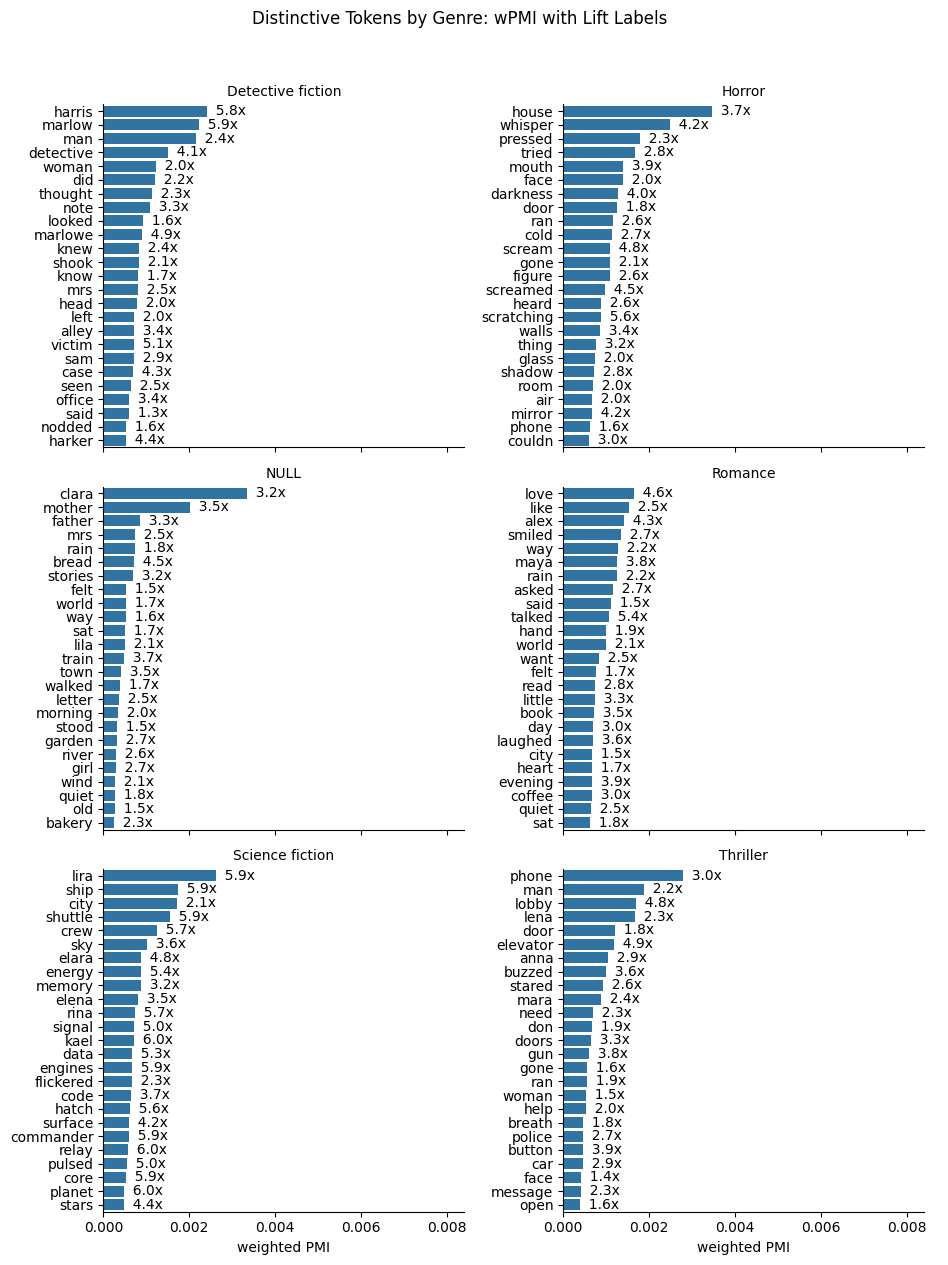

In [34]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
g = sns.catplot(
    data=top_plot,
    x="wPMI",
    y="token",
    col="genre",
    col_wrap=2,
    kind="bar",
    sharey=False,
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.set_axis_labels("weighted PMI", "")
g.set_titles("{col_name}")

for genre, ax in g.axes_dict.items():
    subset = top_plot[top_plot["genre"] == genre]

    for patch, (_, row) in zip(ax.patches, subset.iterrows()):
        x_pos = patch.get_width()
        y_pos = patch.get_y() + patch.get_height() / 2

        ax.text(
            x_pos,
            y_pos,
            f"  {row['lift']:.1f}x",
            va="center",
            ha="left",
        )

    ax.set_xlim(right=ax.get_xlim()[1] * 1.15)

g.fig.suptitle(
    "Distinctive Tokens by Genre: wPMI with Lift Labels", y=1.05
)
save_figure(RESULTS_DIR / "figure-02.png")


In [35]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
probs = np.exp(log_p_t_given_g)
P = pd.DataFrame(probs, index=classes, columns=feature_names)


In [36]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
explicit_genres = []
for genre in classes:
    if genre == "NULL":
        continue

    explicit_genres.append(genre)

Q = P.loc[explicit_genres].to_numpy()
p_null = P.loc["NULL"].to_numpy()


In [37]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
kld = np.apply_along_axis(lambda q: entropy(P.loc["NULL"], q), axis=1, arr=Q)


In [38]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
kld_plot = pd.DataFrame({"KLD": kld, "genre": explicit_genres})
kld_plot.sort_values("KLD", ascending=True, inplace=True)


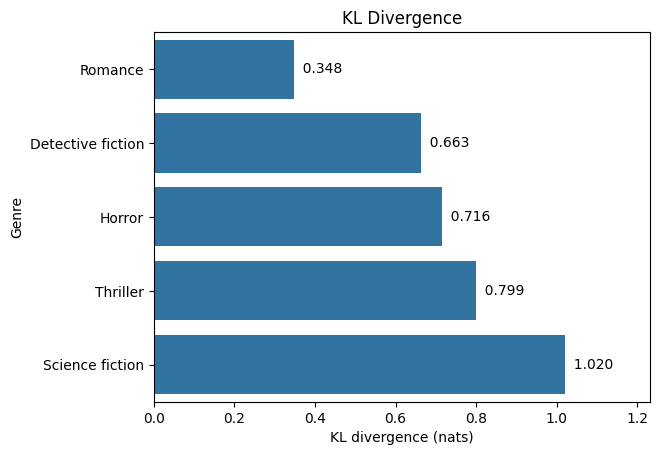

In [39]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
fig, ax = plt.subplots()
sns.barplot(data=kld_plot, x="KLD", y="genre", ax=ax)
ax.set(title="KL Divergence", xlabel="KL divergence (nats)", ylabel="Genre")

for patch, label in zip(ax.containers[0].patches, kld_plot["KLD"]):
    x_pos = patch.get_width()
    y_pos = patch.get_y() + patch.get_height() / 2
    ax.text(
        x_pos,
        y_pos,
        f"  {label:.3f}",
        va="center",
        ha="left",
     )

ax.set_xlim(right=ax.get_xlim()[1] * 1.15)
save_figure(RESULTS_DIR / "figure-03.png")


In [40]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
prob_plot = (
    P
    .rename_axis(index="genre", columns="token")
    .stack()
    .rename("probability")
    .reset_index()
)


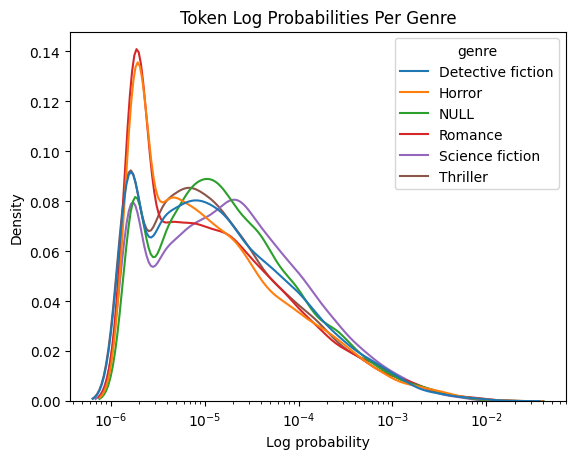

In [41]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
fig, ax = plt.subplots()
sns.kdeplot(
    data=prob_plot,
    x="probability",
    hue="genre",
    multiple="layer",
    log_scale=True,
    ax=ax,
)
ax.set(title="Token Log Probabilities Per Genre", xlabel="Log probability")
save_figure(RESULTS_DIR / "figure-04.png")


In [42]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
def mixture_kl(w):
    """Return KL divergence between NULL and a weighted genre mixture.

    Parameters
    ----------
    w : np.ndarray
        Mixture weights for the explicit genre distributions, shape (n_genre,)

    Returns
    -------
    float
        The KL divergence
    """
    # Construct the mixture distribution: q[t] = sum_g w[g] * Q[g, t]
    q = w @ Q

    # Avoid log(0) if any token receives zero probability and re-normalize so q
    # remains a probability distribution
    q = np.clip(q, 1e-300, None)
    q = q / q.sum()

    return entropy(p_null, q)


In [43]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
x0 = np.ones(len(explicit_genres)) / len(explicit_genres)
constraints = {"type": "eq", "fun": lambda w: w.sum() - 1}
bounds = [(0, 1)] * len(explicit_genres)


In [44]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
res = minimize(
    mixture_kl, x0, method="SLSQP", bounds=bounds, constraints=constraints
)

if not res.success:
    raise RuntimeError(res.message)
else:
    print("OK: optimizer found a solution")


OK: optimizer found a solution


In [45]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
weighting = res.x / res.x.sum()
mix_plot = pd.DataFrame({"mixture": weighting, "genre": explicit_genres})
mix_plot.sort_values("mixture", ascending=False, inplace=True)


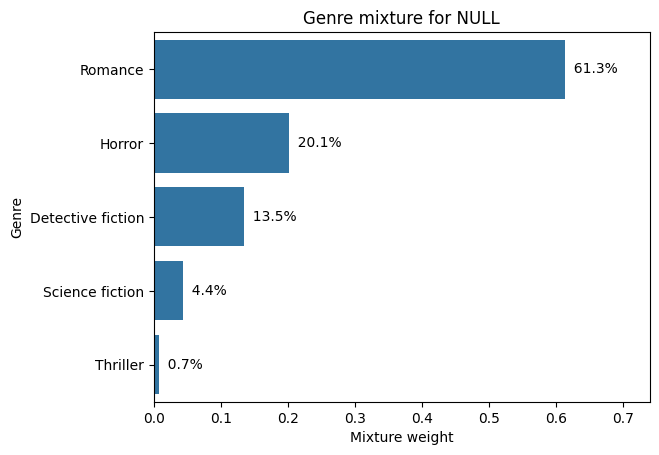

In [46]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
fig, ax = plt.subplots()
sns.barplot(data=mix_plot, x="mixture", y="genre", ax=ax)
ax.set(title="Genre mixture for NULL", xlabel="Mixture weight", ylabel="Genre")

for patch, label in zip(ax.containers[0].patches, mix_plot["mixture"]):
    x_pos = patch.get_width()
    y_pos = patch.get_y() + patch.get_height() / 2
    ax.text(
        x_pos,
        y_pos,
        f"  {label:.1%}",
        va="center",
        ha="left",
     )

ax.set_xlim(right=ax.get_xlim()[1] * 1.15)
save_figure(RESULTS_DIR / "figure-05.png")


In [47]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
best_single = kld_plot.nsmallest(1, "KLD")
improvement = (best_single["KLD"] - res.fun) / best_single["KLD"]
print(f"Mixture improves over romance by {improvement.item():.1%}")


Mixture improves over romance by 40.4%


In [48]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
p_mix = weighting @ Q
residuals = pd.DataFrame({
    "token": feature_names, "p_null": p_null, "p_mix": p_mix
})


In [49]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
residuals["kl_contrib"] = rel_entr(residuals["p_null"], residuals["p_mix"])


In [50]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
k = 25

under = (
    residuals
    .nlargest(k, "kl_contrib")
    .sort_values("kl_contrib", ascending=False)
    .assign(direction="Under-predicted")
)

over = (
    residuals
    .nsmallest(k, "kl_contrib")
    .sort_values("kl_contrib", ascending=False)
    .assign(direction="Over-predicted")
)

kl_plot = pd.concat([under, over], ignore_index=True)


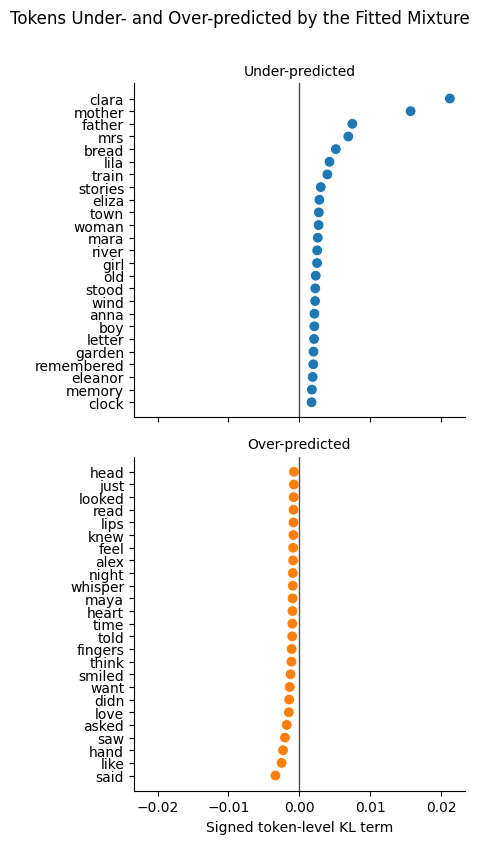

In [51]:
# Course completion: Restore the course token-distribution, weighted PMI, KL mixture, and residual steps.
direction_order = ["Under-predicted", "Over-predicted"]

g = sns.relplot(
    data=kl_plot,
    x="kl_contrib",
    y="token",
    col="direction",
    col_order=direction_order,
    col_wrap=1,
    kind="scatter",
    hue="direction",
    hue_order=direction_order,
    facet_kws={"sharey": False, "sharex": True},
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
    s=60,
    legend=False,
)
g.set_axis_labels("Signed token-level KL term", "")
g.set_titles("{col_name}")

limit = kl_plot["kl_contrib"].abs().max()
for ax in g.axes.flat:
    ax.axvline(0, color="0.3", linewidth=1)
    ax.set_xlim(-limit * 1.1, limit * 1.1)

g.fig.suptitle(
    "Tokens Under- and Over-predicted by the Fitted Mixture",
    y=1.05,
)
save_figure(RESULTS_DIR / "figure-06.png")


In [52]:
top_plot.to_csv(RESULTS_DIR / "top_plot.csv", index=True)
kl_plot.to_csv(RESULTS_DIR / "kl_plot.csv", index=True)
mix_plot.to_csv(RESULTS_DIR / "mix_plot.csv", index=True)
residuals.to_csv(RESULTS_DIR / "residuals.csv", index=True)
observed = {name: module.__version__ for name, module in sys.modules.items()
            if name in {"numpy", "pandas", "torch", "transformers", "sklearn", "scipy", "matplotlib", "seaborn"}}
environment = {"python": platform.python_version(), "imported_packages": observed}
(RESULTS_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print("Completed notebook; results:", RESULTS_DIR)


Completed notebook; results: /content/interpretability-classroom-notebooks/results/session-05
